# Homework 6 – Problem 1: PCA with an Undercomplete Linear Autoencoder

**Hussein Jawad**

The plots of training data on slides 24 and 28 come from another example. Here we generate a
new 3D training set with the provided `generate_3d_data()` function, train the linear
autoencoder from slide 25 on it, and produce our own versions of the two plots:

* the 3D training data (slide 24), and
* the 2D codings produced by the encoder (slide 28).

The code follows the structure of Géron's chapter 18 notebook
(`18_autoencoders_gans_and_diffusion_models.ipynb`), with only the tweaks needed for this problem.

# Setup

This project requires Python 3.10 or above:

In [1]:
import sys  # gives access to the Python interpreter version
assert sys.version_info >= (3, 10)  # fail early if Python is older than 3.10

Are we using Colab or Kaggle?

In [2]:
IS_COLAB = "google.colab" in sys.modules  # True when running inside Google Colab
IS_KAGGLE = "kaggle_secrets" in sys.modules  # True when running inside a Kaggle notebook

If using Colab, the TorchMetrics library is not pre-installed so we must install it manually:

In [3]:
if IS_COLAB:  # only Colab lacks torchmetrics by default
    %pip install -q torchmetrics  # quietly install the TorchMetrics library

We also need PyTorch ≥ 2.6.0:

In [4]:
from packaging.version import Version  # utility to compare version strings correctly
import torch  # the PyTorch deep learning library
assert Version(torch.__version__) >= Version("2.6.0")  # fail early if PyTorch is too old

Use a hardware accelerator if one is available:

In [5]:
if torch.cuda.is_available():  # NVIDIA GPU available?
    device = "cuda"  # use the GPU
elif torch.backends.mps.is_available():  # Apple Silicon GPU available?
    device = "mps"  # use Apple's Metal Performance Shaders
else:  # no accelerator found
    device = "cpu"  # fall back to the CPU (fine for this tiny model)
device  # display the selected device

'cpu'

Define the default font sizes to make the figures prettier:

In [6]:
import matplotlib.pyplot as plt  # plotting library
plt.rc('font', size=14)  # default text size
plt.rc('axes', labelsize=14, titlesize=14)  # axis label and title sizes
plt.rc('legend', fontsize=14)  # legend text size
plt.rc('xtick', labelsize=10)  # x-axis tick label size
plt.rc('ytick', labelsize=10)  # y-axis tick label size

We use the same `evaluate_tm()` and `train()` functions as in Géron's notebook
(with gradient clipping and support for named-tuple outputs):

In [7]:
import torchmetrics  # library of ready-made metrics (e.g., RMSE)

def evaluate_tm(model, data_loader, metric):
    model.eval()  # switch the model to evaluation mode
    metric.reset()  # clear any previously accumulated metric state
    with torch.no_grad():  # no gradients needed for evaluation
        for X_batch, y_batch in data_loader:  # loop over the evaluation batches
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)  # move batch to the device
            y_pred = model(X_batch)  # forward pass
            if isinstance(y_pred, tuple):  # some models return a named tuple
                y_pred = y_pred.output  # keep only the main output
            metric.update(y_pred, y_batch)  # accumulate the metric for this batch
    return metric.compute()  # return the metric over the whole dataset

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, patience=2, factor=0.5, epoch_callback=None):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=patience, factor=factor)  # scale LR by `factor` when the valid metric plateaus
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}  # learning curves
    for epoch in range(n_epochs):  # loop over the epochs
        total_loss = 0.0  # running sum of the batch losses
        metric.reset()  # reset the training metric at the start of each epoch
        model.train()  # switch the model to training mode
        if epoch_callback is not None:  # optional hook called at each epoch
            epoch_callback(model, epoch)  # e.g., to adjust the model during training
        for index, (X_batch, y_batch) in enumerate(train_loader):  # loop over training batches
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)  # move batch to the device
            y_pred = model(X_batch)  # forward pass: reconstruct the inputs
            loss = loss_fn(y_pred, y_batch)  # reconstruction loss (MSE)
            total_loss += loss.item()  # accumulate the loss as a Python float
            loss.backward()  # backpropagation: compute the gradients
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # clip gradients for stability
            optimizer.step()  # gradient descent step
            optimizer.zero_grad()  # reset the gradients for the next batch
            if isinstance(y_pred, tuple):  # some models return a named tuple
                y_pred = y_pred.output  # keep only the main output
            metric.update(y_pred, y_batch)  # accumulate the training metric
            train_metric = metric.compute().item()  # current training metric value
            print(f"\rBatch {index + 1}/{len(train_loader)}", end="")  # progress: batch number
            print(f", loss={total_loss/(index+1):.4f}", end="")  # progress: mean loss so far
            print(f", {train_metric=:.3f}", end="")  # progress: training metric so far
        history["train_losses"].append(total_loss / len(train_loader))  # mean epoch loss
        history["train_metrics"].append(train_metric)  # final training metric of the epoch
        val_metric = evaluate_tm(model, valid_loader, metric).item()  # validation metric
        history["valid_metrics"].append(val_metric)  # record it
        scheduler.step(val_metric)  # let the scheduler adapt the learning rate
        print(f"\rEpoch {epoch + 1}/{n_epochs},                      "  # end-of-epoch summary
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.3}, "
              f"valid metric: {history['valid_metrics'][-1]:.3}")
    return history  # return the learning curves

# Performing PCA with an Undercomplete Linear Autoencoder

Let's build the autoencoder (slide 25): 3D inputs, a 2D coding layer, and 3D outputs.

In [8]:
import torch.nn as nn  # neural network building blocks

torch.manual_seed(42)  # make weight initialization reproducible
encoder = nn.Linear(3, 2)  # encoder: maps 3D inputs to 2D codings
decoder = nn.Linear(2, 3)  # decoder: maps 2D codings back to 3D reconstructions
autoencoder = nn.Sequential(encoder, decoder).to(device)  # chain them and move to the device

Now let's generate the **new** 3D dataset using the code given in Problem 1
(instead of the Chapter 7 dataset used in Géron's notebook), and center it:

In [9]:
import numpy as np  # numerical arrays

np.random.seed(4)  # make the generated dataset reproducible

def generate_3d_data(m, w1=0.1, w2=0.3, noise=0.1):
    angles = np.random.rand(m) * 3 * np.pi / 2 - 0.5  # random angles in [-0.5, 3π/2 - 0.5)
    data = np.empty((m, 3))  # allocate an m x 3 array
    data[:, 0] = np.cos(angles) + np.sin(angles)/2 + noise * np.random.randn(m) / 2  # x: curved, noisy
    data[:, 1] = np.sin(angles) * 0.7 + noise * np.random.randn(m) / 2  # y: curved, noisy
    data[:, 2] = data[:, 0] * w1 + data[:, 1] * w2 + noise * np.random.randn(m)  # z: near the plane w1*x + w2*y
    return data  # return the 3D dataset

X_train = generate_3d_data(60)  # 60 training instances
X_train = X_train - X_train.mean(axis=0, keepdims=0)  # center the data (as PCA assumes)

Géron's `train()` function also needs a validation set, so we draw 500 more instances from the
same distribution (after `X_train`, so `X_train` is unchanged) and center them the same way:

In [10]:
X_valid = generate_3d_data(500)  # 500 validation instances from the same distribution
X_valid = X_valid - X_valid.mean(axis=0, keepdims=0)  # center it the same way as X_train

Let's plot the 3D training data (our version of the slide 24 plot):

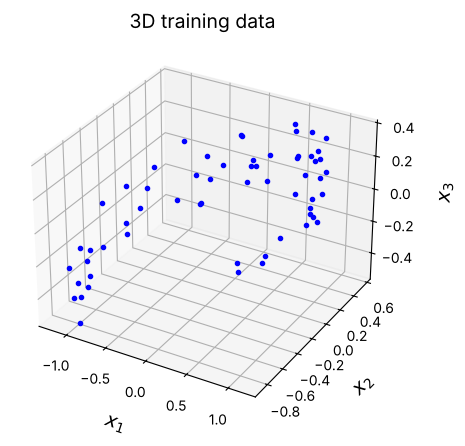

In [11]:
fig = plt.figure(figsize=(6, 5))  # create a new figure
ax = fig.add_subplot(projection="3d")  # add 3D axes
ax.plot(X_train[:, 0], X_train[:, 1], X_train[:, 2], "b.")  # scatter the 3D training points
ax.set_xlabel("$x_1$", labelpad=10)  # label the first axis
ax.set_ylabel("$x_2$", labelpad=10)  # label the second axis
ax.set_zlabel("$x_3$", labelpad=10)  # label the third axis
ax.set_title("3D training data")  # figure title
plt.show()  # display the figure

Wrap the data in `DataLoader`s. For an autoencoder the targets are the inputs themselves:

In [12]:
from torch.utils.data import DataLoader, TensorDataset  # data pipeline utilities

X_train_t = torch.from_numpy(X_train.astype(np.float32))  # NumPy float64 -> float32 tensor
X_valid_t = torch.from_numpy(X_valid.astype(np.float32))  # same for the validation set
train_set = TensorDataset(X_train_t, X_train_t)  # (input, target) pairs: target = input
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)  # shuffled mini-batches of 32
valid_set = TensorDataset(X_valid_t, X_valid_t)  # validation (input, target) pairs
valid_loader = DataLoader(valid_set, batch_size=32)  # validation mini-batches (no shuffling)

Train the autoencoder to reconstruct its inputs (same hyperparameters as Géron's notebook):

In [13]:
torch.manual_seed(42)  # reproducible shuffling
optimizer = torch.optim.NAdam(autoencoder.parameters(), lr=0.2)  # NAdam optimizer
mse = nn.MSELoss()  # reconstruction loss: mean squared error
rmse = torchmetrics.MeanSquaredError(squared=False).to(device)  # metric: root mean squared error
history = train(autoencoder, optimizer, mse, rmse, train_loader, valid_loader,
                n_epochs=20)  # train for 20 epochs

Epoch 1/20,                      train loss: 0.2755, train metric: 0.528, valid metric: 0.329
Epoch 2/20,                      train loss: 0.0846, train metric: 0.294, valid metric: 0.243
Epoch 3/20,                      train loss: 0.0521, train metric: 0.227, valid metric: 0.217
Epoch 4/20,                      train loss: 0.0482, train metric: 0.22, valid metric: 0.214
Epoch 5/20,                      train loss: 0.0412, train metric: 0.204, valid metric: 0.189
Epoch 6/20,                      train loss: 0.0341, train metric: 0.185, valid metric: 0.155
Epoch 7/20,                      train loss: 0.0220, train metric: 0.148, valid metric: 0.116
Epoch 8/20,                      train loss: 0.0121, train metric: 0.111, valid metric: 0.0979
Epoch 9/20,                      train loss: 0.0089, train metric: 0.0945, valid metric: 0.0831
Epoch 10/20,                      train loss: 0.0066, train metric: 0.0815, valid metric: 0.0731
Epoch 11/20,                      train loss: 0.0053, t

Use the encoder alone to project the training data onto the 2D coding space:

In [14]:
with torch.no_grad():  # no gradients needed for inference
    codings = encoder(X_train_t.to(device))  # 60 x 2 codings (the PCA-like projection)

Plot the 2D codings (our version of the slide 28 plot):

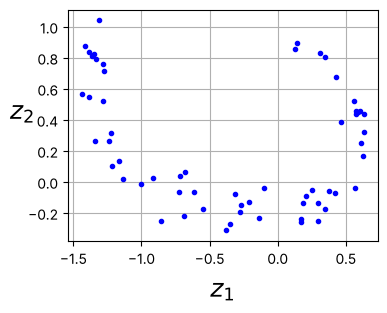

In [15]:
fig = plt.figure(figsize=(4, 3))  # create a new figure
codings_np = codings.cpu().numpy()  # move codings to the CPU and convert to NumPy
plt.plot(codings_np[:, 0], codings_np[:, 1], "b.")  # scatter the 2D codings
plt.xlabel("$z_1$", fontsize=18)  # first coding dimension
plt.ylabel("$z_2$", fontsize=18, rotation=0)  # second coding dimension
plt.grid(True)  # add a grid
plt.show()  # display the figure

**Observation:** the linear autoencoder found the 2D plane that best preserves the variance of
the data (just like PCA), so the 2D codings keep the curved, arc-shaped structure of the 3D
training set while dropping the low-variance direction (mostly the noise around the plane
$x_3 \approx 0.1x_1 + 0.3x_2$). As with PCA, the codings may be rotated/scaled compared to the
original axes, since the autoencoder does not constrain its coding axes to be orthonormal.